In [1]:
#setup and load both models
import os, sys, time, json
if os.path.basename(os.getcwd()) == "notebooks":
    os.chdir("..")
sys.path.append(os.getcwd())

import numpy as np, torch, matplotlib.pyplot as plt
from src.config import N, NUM_CELLS, SEP, MASK
from src.groups import LEVEL_FLAT, NUM_LEVELS
from src.dataset import load
from src.sudoku import is_valid, count_violations
from src.models import SudokuGPT, NCMLite

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
te_p, te_s = load("test")
P = torch.tensor(te_p.reshape(len(te_p), -1), dtype=torch.long)    # puzzles (CPU)
S = te_s.reshape(len(te_s), -1).astype(int)                         # solutions
clues = (te_p.reshape(len(te_p), -1) > 0).sum(1)
LEVEL = torch.tensor(LEVEL_FLAT, device=device)

ar = SudokuGPT().to(device)
ar.load_state_dict(torch.load("checkpoints/ar_best.pt", map_location=device)); ar.eval()
ncm = NCMLite().to(device)
ncm.load_state_dict(torch.load("checkpoints/ncm_best.pt", map_location=device)); ncm.eval()
print("Both models loaded. Test puzzles:", len(P))

Both models loaded. Test puzzles: 1000


In [2]:
#the two solver
@torch.no_grad()
def solve_ar(puz):                                   # 36 sequential passes
    seq = torch.cat([puz, torch.full((len(puz), 1), SEP, device=puz.device)], 1)
    for i in range(NUM_CELLS):
        nxt = ar(seq)[:, -1, 1:N + 1].argmax(-1) + 1
        nxt = torch.where(puz[:, i] > 0, puz[:, i], nxt)
        seq = torch.cat([seq, nxt[:, None]], 1)
    return seq[:, NUM_CELLS + 1:]

@torch.no_grad()
def solve_ncm(puz):                                  # 3 passes
    state = torch.where(puz > 0, puz, torch.full_like(puz, MASK))
    for k in range(NUM_LEVELS):
        kk = torch.full((len(puz),), k, dtype=torch.long, device=puz.device)
        pred = ncm(state, kk)[:, :, 1:N + 1].argmax(-1) + 1
        state = torch.where((LEVEL[None, :] == k) & (state == MASK), pred, state)
    return state

def run(solver, bs=500):
    out = [solver(P[i:i + bs].to(device)).cpu() for i in range(0, len(P), bs)]
    return torch.cat(out).numpy()

preds = {"Transformer": run(solve_ar), "NCM-lite": run(solve_ncm)}
print("Solved all", len(P), "test puzzles with both models")

Solved all 1000 test puzzles with both models


In [3]:
#overall results with margin of error
def per_puzzle(pr):
    grids = pr.reshape(-1, N, N)
    return {"solved": np.array([is_valid(g) for g in grids]) & (pr == S).all(1),
            "wrong": (pr != S).sum(1),
            "viol": np.array([count_violations(g) for g in grids]),
            "cell_acc": (pr == S).mean(1)}

stats = {name: per_puzzle(pr) for name, pr in preds.items()}

def moe(p, n):
    return 1.96 * np.sqrt(p * (1 - p) / n)

print(f"{'model':12s} {'solved %':>16s} {'cell acc %':>11s} {'violations':>11s}")
for name, s in stats.items():
    p = s["solved"].mean()
    print(f"{name:12s} {p*100:9.1f} ±{moe(p, len(P))*100:4.1f} "
          f"{s['cell_acc'].mean()*100:11.1f} {s['viol'].mean():11.2f}")

model                solved %  cell acc %  violations
Transformer       53.2 ± 3.1        90.1        2.09
NCM-lite          71.5 ± 2.8        96.3        1.14


In [4]:
#accuracy by difficulty (fewer clues = harder)
buckets = [(12, 15, "hard (12-15)"), (16, 19, "medium (16-19)"), (20, 24, "easy (20-24)")]
by_bucket = {name: [] for name in stats}
print(f"{'bucket':16s} {'n':>5s} " + " ".join(f"{n:>12s}" for n in stats))
for lo, hi, label in buckets:
    m = (clues >= lo) & (clues <= hi)
    row = [stats[n]["solved"][m].mean() * 100 for n in stats]
    for n, v in zip(stats, row):
        by_bucket[n].append(v)
    print(f"{label:16s} {m.sum():5d} " + " ".join(f"{v:11.1f}%" for v in row))

bucket               n  Transformer     NCM-lite
hard (12-15)       288        18.8%        32.6%
medium (16-19)     331        51.7%        75.8%
easy (20-24)       381        80.6%        97.1%


In [5]:
#speed at batch size 500 and batch size 1
def sync():
    if device.type == "cuda": torch.cuda.synchronize()

def ms_per_puzzle(solver, n, bs):
    solver(P[:bs].to(device)); sync()                      # warm-up
    t = time.time()
    for i in range(0, n, bs):
        solver(P[i:i + bs].to(device))
    sync()
    return (time.time() - t) / n * 1000

timing = {}
for name, solver in [("Transformer", solve_ar), ("NCM-lite", solve_ncm)]:
    timing[name] = {"batch500": ms_per_puzzle(solver, 500, 500),
                    "batch1": ms_per_puzzle(solver, 100, 1)}
    print(f"{name:12s} batch 500: {timing[name]['batch500']:7.2f} ms/puzzle | "
          f"batch 1: {timing[name]['batch1']:7.2f} ms/puzzle")
print("Speed-up at batch 1:", round(timing["Transformer"]["batch1"] / timing["NCM-lite"]["batch1"], 1), "x")

Transformer  batch 500:   10.37 ms/puzzle | batch 1:  291.34 ms/puzzle
NCM-lite     batch 500:    0.55 ms/puzzle | batch 1:   19.58 ms/puzzle
Speed-up at batch 1: 14.9 x


In [6]:
#how wrong are the failures
for name, s in stats.items():
    failed = ~s["solved"]
    w = s["wrong"][failed]
    print(f"{name:12s}: {failed.sum()} failed puzzles | wrong cells per failure: "
          f"median {np.median(w):.0f}, mean {w.mean():.1f}")

Transformer : 468 failed puzzles | wrong cells per failure: median 7, mean 7.6
NCM-lite    : 285 failed puzzles | wrong cells per failure: median 4, mean 4.7


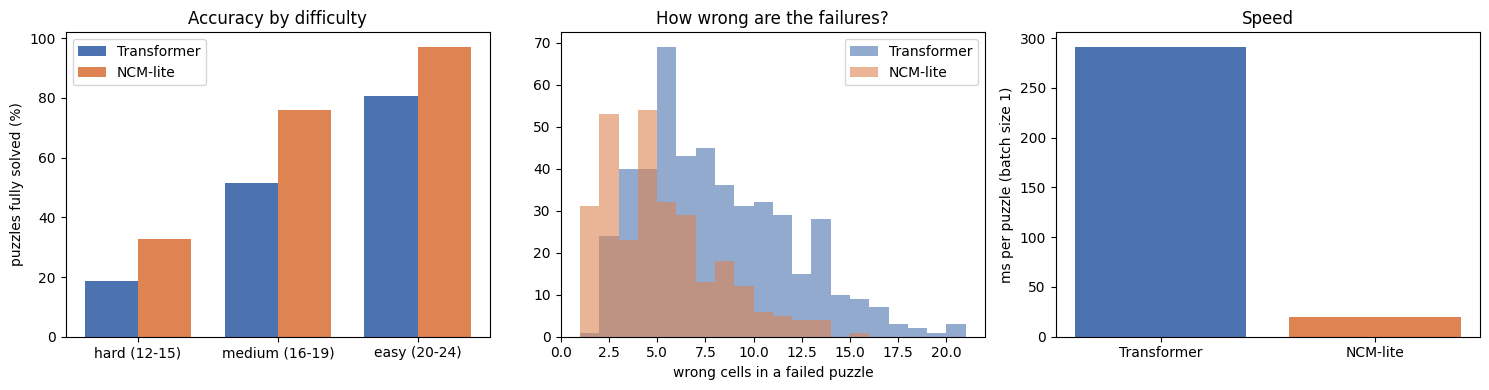

Saved results/comparison.png and results/phase5_summary.json


In [7]:
#charts
colors = {"Transformer": "#4C72B0", "NCM-lite": "#DD8452"}
fig, ax = plt.subplots(1, 3, figsize=(15, 4))

x = np.arange(len(buckets)); w = 0.38
for j, name in enumerate(stats):
    ax[0].bar(x + (j - 0.5) * w, by_bucket[name], w, label=name, color=colors[name])
ax[0].set_xticks(x); ax[0].set_xticklabels([b[2] for b in buckets])
ax[0].set_ylabel("puzzles fully solved (%)"); ax[0].set_title("Accuracy by difficulty")
ax[0].legend()

for name, s in stats.items():
    ax[1].hist(s["wrong"][~s["solved"]], bins=range(1, 22), alpha=0.6,
               label=name, color=colors[name])
ax[1].set_xlabel("wrong cells in a failed puzzle"); ax[1].set_title("How wrong are the failures?")
ax[1].legend()

names = list(timing)
ax[2].bar([0, 1], [timing[n]["batch1"] for n in names], color=[colors[n] for n in names])
ax[2].set_xticks([0, 1]); ax[2].set_xticklabels(names)
ax[2].set_ylabel("ms per puzzle (batch size 1)"); ax[2].set_title("Speed")
plt.tight_layout()
plt.savefig("results/comparison.png", dpi=150)
plt.show()

summary = {
    "solved_pct": {n: float(s["solved"].mean()) for n, s in stats.items()},
    "cell_acc": {n: float(s["cell_acc"].mean()) for n, s in stats.items()},
    "avg_violations": {n: float(s["viol"].mean()) for n, s in stats.items()},
    "by_difficulty": {n: dict(zip([b[2] for b in buckets], by_bucket[n])) for n in stats},
    "timing_ms": timing,
    "passes": {"Transformer": 36, "NCM-lite": 3},
}
json.dump(summary, open("results/phase5_summary.json", "w"), indent=2)
print("Saved results/comparison.png and results/phase5_summary.json")